In [26]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
# 1. Load data and verify structure and uniqueness of IDs (Requirements C2 and C3)
uds = pd.read_csv('../udslong_imputed.csv')
mri = pd.read_csv('../mriscanclean.csv')
# 2. Merge both datasets (UDS + MRI) based on subject ID
df_merged = pd.merge(uds, mri.drop(columns=['NACCUDSD']), on='NACCID', how='inner')
df_clean = df_merged.copy()
df_clean.loc[df_clean['EDUC'] > 36, 'EDUC'] = np.nan
df_clean.loc[df_clean['MOCATOTS'] > 30, 'MOCATOTS'] = np.nan
df_clean.loc[df_clean['ANIMALS'] >= 95, 'ANIMALS'] = np.nan
df_clean.loc[df_clean['VEG'] >= 95, 'VEG'] = np.nan
df_clean.loc[df_clean['TRAILA'] > 150, 'TRAILA'] = np.nan
df_clean.loc[df_clean['TRAILB'] > 300, 'TRAILB'] = np.nan
df_clean.loc[df_clean['LH_ENTORHINAL_GVOL'] <= 0, 'LH_ENTORHINAL_GVOL'] = np.nan
df_target = df_clean[df_clean['NACCUDSD'].isin([3.0, 4.0])].copy()
N_total = len(df_target)

In [28]:
# ==========================================
# 2. Define Events A, B, and C (Using Index Sets & Boolean Masks)
# ==========================================
# Event A: Patient has MCI (NACCUDSD == 3.0)
index_MCI = df_target[df_target['NACCUDSD'] == 3.0].index

# Event B: Mean Entorhinal Cortical Thickness (Left & Right) > Median
data_ENTORHINAL_AVGTH = (df_target['LH_ENTORHINAL_AVGTH'] + df_target['RH_ENTORHINAL_AVGTH']) / 2
df_target['ENTORHINAL_AVGTH_MEAN'] = data_ENTORHINAL_AVGTH
median_ent = np.percentile(data_ENTORHINAL_AVGTH, 50)
index_ENTORHINAL_AVGTH = data_ENTORHINAL_AVGTH[data_ENTORHINAL_AVGTH > median_ent].index

# Event C: Years of Education > 12
index_education = df_target[df_target['EDUC'] > 12].index

print(f"Total Target Sample Size (N): {N_total}")
print(f"Median of Mean Entorhinal Thickness (L & R): {median_ent:.4f} mm")
print(f"Count(A - MCI): {len(index_MCI)}")
print(f"Count(B - Entorhinal > Median): {len(index_ENTORHINAL_AVGTH)}")
print(f"Count(C - EDUC > 12): {len(index_education)}")


Total Target Sample Size (N): 383
Median of Mean Entorhinal Thickness (L & R): 2.8745 mm
Count(A - MCI): 252
Count(B - Entorhinal > Median): 191
Count(C - EDUC > 12): 327


In [29]:
# ==========================================
# 3. Marginal, Joint, and Conditional Probabilities (Tasks 1, 2, 3 & Requirements C1, C3)
# ==========================================
# Marginal Probabilities
P_A = len(index_MCI) / N_total
P_B = len(index_ENTORHINAL_AVGTH) / N_total
P_C = len(index_education) / N_total  # Note: out of N=383 (or 327/382 = 0.8560 on non-missing EDUC)

# Joint Probabilities (Intersections of Index Sets)
index_A_and_B = index_MCI.intersection(index_ENTORHINAL_AVGTH)
index_A_and_C = index_MCI.intersection(index_education)
index_B_and_C = index_ENTORHINAL_AVGTH.intersection(index_education)

P_AB = len(index_A_and_B) / N_total
P_AC = len(index_A_and_C) / N_total
P_BC = len(index_B_and_C) / N_total

# Conditional Probabilities
P_A_given_B = P_AB / P_B
P_B_given_A = P_AB / P_A

# Complement of B (Entorhinal <= Median) and Complement of A (Dementia, NACCUDSD == 4.0)
index_not_B = df_target.index.difference(index_ENTORHINAL_AVGTH)
index_not_A = df_target.index.difference(index_MCI)
index_not_C = df_target.index.difference(index_education)

P_A_given_notB = len(index_MCI.intersection(index_not_B)) / len(index_not_B)
P_B_given_notA = len(index_ENTORHINAL_AVGTH.intersection(index_not_A)) / len(index_not_A)
P_A_given_C = len(index_A_and_C) / len(index_education)
P_A_given_notC = len(index_MCI.intersection(index_not_C)) / len(index_not_C)

prob_summary = pd.DataFrame([
    {'Metric': 'P(A) [MCI: NACCUDSD=3]', 'Empirical_Value': round(P_A, 4), 'Comparison / Reference': f'Count = {len(index_MCI)}/{N_total}'},
    {'Metric': 'P(B) [Mean Entorhinal > Median]', 'Empirical_Value': round(P_B, 4), 'Comparison / Reference': f'Count = {len(index_ENTORHINAL_AVGTH)}/{N_total}'},
    {'Metric': 'P(C) [EDUC > 12 Years]', 'Empirical_Value': round(P_C, 4), 'Comparison / Reference': f'Count = {len(index_education)}/{N_total}'},
    {'Metric': 'P(A ∩ B) [Joint A and B]', 'Empirical_Value': round(P_AB, 4), 'Comparison / Reference': f'P(A)*P(B) = {P_A*P_B:.4f} (Diff = +{P_AB - P_A*P_B:.4f})'},
    {'Metric': 'P(A ∩ C) [Joint A and C]', 'Empirical_Value': round(P_AC, 4), 'Comparison / Reference': f'P(A)*P(C) = {P_A*P_C:.4f} (Diff = +{P_AC - P_A*P_C:.4f})'},
    {'Metric': 'P(B ∩ C) [Joint B and C]', 'Empirical_Value': round(P_BC, 4), 'Comparison / Reference': f'P(B)*P(C) = {P_B*P_C:.4f} (Diff = {P_BC - P_B*P_C:.4f})'},
    {'Metric': 'P(A | B) [MCI given Thick > Med]', 'Empirical_Value': round(P_A_given_B, 4), 'Comparison / Reference': f'P(A | B\') = {P_A_given_notB:.4f}'},
    {'Metric': 'P(B | A) [Thick > Med given MCI]', 'Empirical_Value': round(P_B_given_A, 4), 'Comparison / Reference': f'P(B | A\') = {P_B_given_notA:.4f}'},
    {'Metric': 'P(A | C) [MCI given EDUC > 12]', 'Empirical_Value': round(P_A_given_C, 4), 'Comparison / Reference': f'P(A | C\') = {P_A_given_notC:.4f}'}
])
print("\n--- Summary of Marginal, Joint, and Conditional Probabilities ---")
print(prob_summary.to_string(index=False))


--- Summary of Marginal, Joint, and Conditional Probabilities ---
                          Metric  Empirical_Value              Comparison / Reference
          P(A) [MCI: NACCUDSD=3]           0.6580                     Count = 252/383
 P(B) [Mean Entorhinal > Median]           0.4987                     Count = 191/383
          P(C) [EDUC > 12 Years]           0.8538                     Count = 327/383
        P(A ∩ B) [Joint A and B]           0.3890 P(A)*P(B) = 0.3281 (Diff = +0.0609)
        P(A ∩ C) [Joint A and C]           0.5692 P(A)*P(C) = 0.5618 (Diff = +0.0074)
        P(B ∩ C) [Joint B and C]           0.4125 P(B)*P(C) = 0.4258 (Diff = -0.0132)
P(A | B) [MCI given Thick > Med]           0.7801                  P(A | B') = 0.5365
P(B | A) [Thick > Med given MCI]           0.5913                  P(B | A') = 0.3206
  P(A | C) [MCI given EDUC > 12]           0.6667                  P(A | C') = 0.6071


In [30]:
# ==========================================
# 4. Random Variables, Empirical Mean & Variance (Tasks 4 & 5)
# ==========================================
# Random Variable 1 (Discrete): MOCATOTS
# Random Variable 2 (Continuous): LH_ENTORHINAL_AVGTH
moca_s = df_target['MOCATOTS'].dropna()
ent_lh_s = df_target['LH_ENTORHINAL_AVGTH'].dropna()

rv_table = pd.DataFrame([
    {
        'Random_Variable': 'MOCATOTS (Discrete)',
        'Valid_N': len(moca_s),
        'Empirical_Mean': round(moca_s.mean(), 4),
        'Sample_Variance (s^2)': round(moca_s.var(ddof=1), 4),
        'Std_Dev (s)': round(moca_s.std(ddof=1), 4),
    },
    {
        'Random_Variable': 'LH_ENTORHINAL_AVGTH (Continuous)',
        'Valid_N': len(ent_lh_s),
        'Empirical_Mean': round(ent_lh_s.mean(), 4),
        'Sample_Variance (s^2)': round(ent_lh_s.var(ddof=1), 4),
        'Std_Dev (s)': round(ent_lh_s.std(ddof=1), 4),
    }
])
print("\n--- Random Variables: Empirical Mean, Variance & Shape ---")
print(rv_table.to_string(index=False))


--- Random Variables: Empirical Mean, Variance & Shape ---
                 Random_Variable  Valid_N  Empirical_Mean  Sample_Variance (s^2)  Std_Dev (s)
             MOCATOTS (Discrete)      379         20.4016                27.8979       5.2818
LH_ENTORHINAL_AVGTH (Continuous)      383          2.7985                 0.1823       0.4269


In [31]:
# ==========================================
# 5. Binomial Model Evaluation (Task 6)
# ==========================================
# Define X = number of MCI patients (Event A) in a random sample of n = 15 impaired patients
n_trials = 30
p_success = P_A
binom_mean = n_trials * p_success
binom_var = n_trials * p_success * (1 - p_success)
prob_exact_10 = stats.binom.pmf(10, n_trials, p_success)
prob_at_least_10 = 1 - stats.binom.cdf(9, n_trials, p_success)

print(f"\n--- Binomial Model: X ~ Bin(n={n_trials}, p={p_success:.4f}) ---")
print(f"Theoretical Mean E[X] = {binom_mean:.4f}, Variance Var(X) = {binom_var:.4f}")
print(f"P(X = 10) = {prob_exact_10:.4f}, P(X >= 10) = {prob_at_least_10:.4f}")


--- Binomial Model: X ~ Bin(n=30, p=0.6580) ---
Theoretical Mean E[X] = 19.7389, Variance Var(X) = 6.7514
P(X = 10) = 0.0002, P(X >= 10) = 0.9999



--- Requirement C2: Conditional Distribution of LH_ENTORHINAL_AVGTH by Clinical Group ---
            N    Mean  Variance      SD  Median     IQR
NACCUDSD                                               
3.0       252  2.8633    0.1863  0.4316    2.92  0.5685
4.0       131  2.6739    0.1521  0.3900    2.67  0.5190

--- Task 8 & Requirement C4: Joint Variability (LH_ENTORHINAL_AVGTH vs. MOCATOTS, N=379) ---
Sample Covariance Cov(X, Y) = 0.4486

 detect outliers for MOCATOTS ---
Q1: 18.0000, Q3: 24.0000, IQR: 6.0000
(Lower Bound): 9.0000
(Upper Bound): 33.0000
Number of Outliers: 18 data points out of 379 valid data points
Outlier Values: [0.0, 2.0, 3.0, 3.0, 4.0, 5.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 8.0, 8.0, 8.0, 8.0, 8.0, 8.0]

 detect outliers for LH_ENTORHINAL_AVGTH ---
Q1: 2.5120, Q3: 3.1035, IQR: 0.5915
(Lower Bound): 1.6247
(Upper Bound): 3.9908
Number of Outliers: 3 data points out of 383 valid data points
Outlier Values: [1.276, 1.451, 1.566]


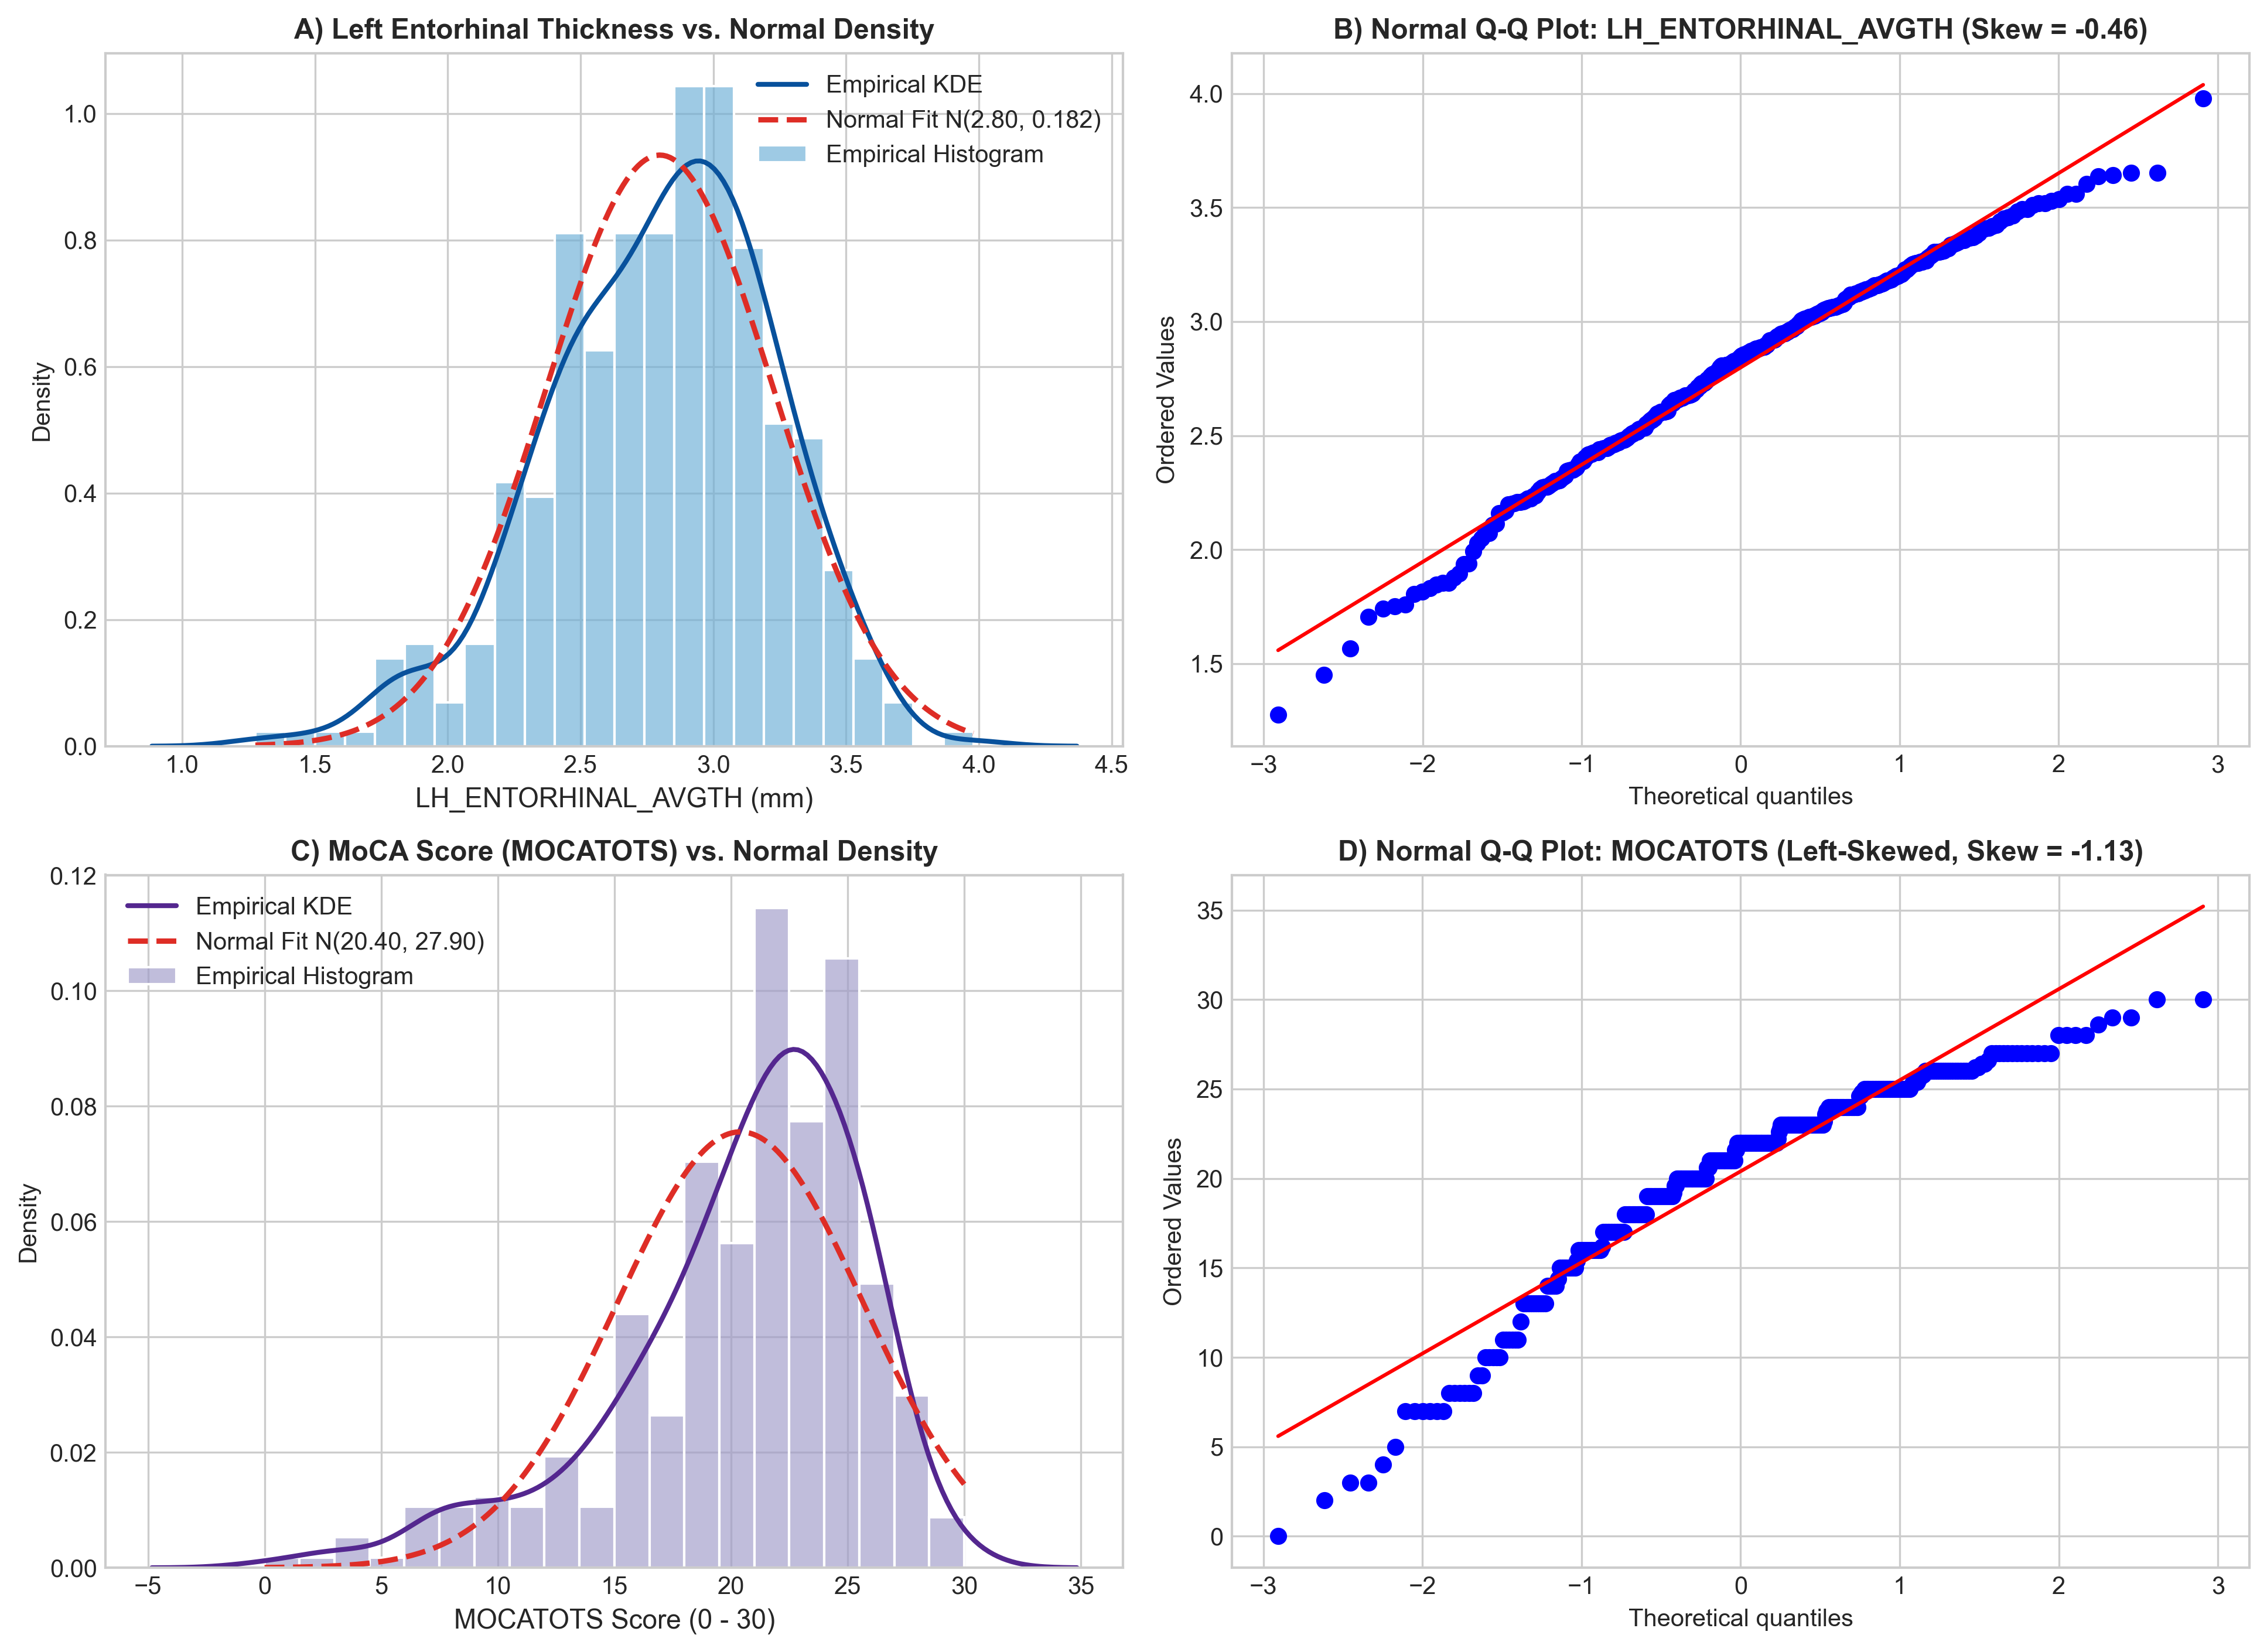

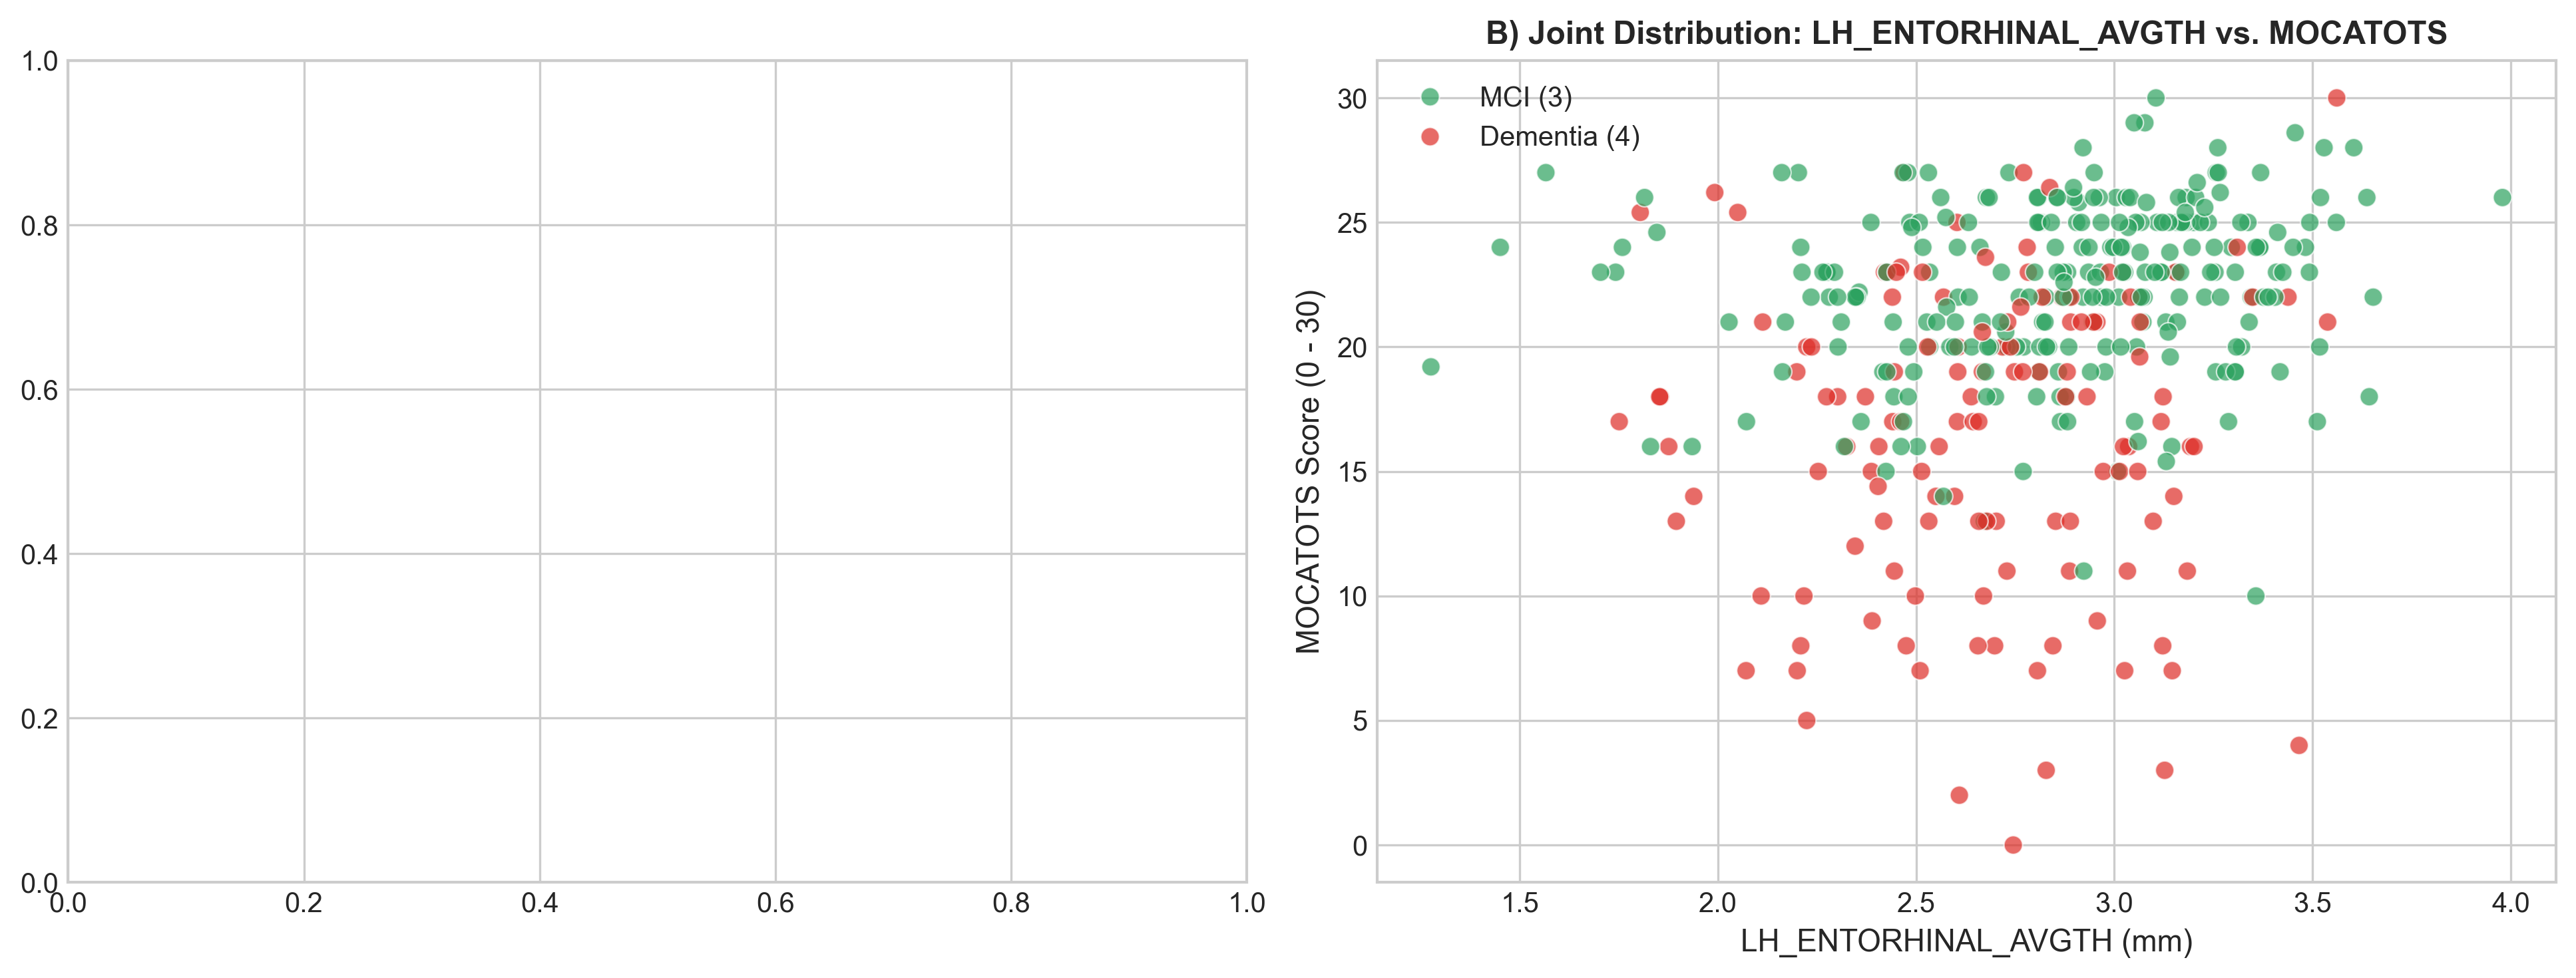

In [51]:
# ==========================================
# 6. Conditional MRI Distribution & Joint Variability / Covariance (Task 8 & Requirements C2, C4)
# ==========================================
print("\n--- Requirement C2: Conditional Distribution of LH_ENTORHINAL_AVGTH by Clinical Group ---")
cond_mri = df_target.groupby('NACCUDSD')['LH_ENTORHINAL_AVGTH'].agg(
    N='count', Mean='mean', Variance='var', SD='std', Median='median',
    IQR=lambda x: np.percentile(x, 75) - np.percentile(x, 25)
).round(4)
print(cond_mri)

# Joint Covariance and Correlation between LH_ENTORHINAL_AVGTH and MOCATOTS
df_joint = df_target[['MOCATOTS', 'LH_ENTORHINAL_AVGTH', 'ENTORHINAL_AVGTH_MEAN', 'NACCUDSD']].dropna()
cov_lh_moca = df_joint[['LH_ENTORHINAL_AVGTH', 'MOCATOTS']].cov().iloc[0, 1]

print(f"\n--- Task 8 & Requirement C4: Joint Variability (LH_ENTORHINAL_AVGTH vs. MOCATOTS, N={len(df_joint)}) ---")
print(f"Sample Covariance Cov(X, Y) = {cov_lh_moca:.4f}")
# ==========================================
# Outliers data
# ==========================================

def detect_outliers_iqr(series, name):
    s = series.dropna()
    q1 = np.percentile(s, 25)
    q3 = np.percentile(s, 75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = s[(s < lower_bound) | (s > upper_bound)]
    
    print(f"\n detect outliers for {name} ---")
    print(f"Q1: {q1:.4f}, Q3: {q3:.4f}, IQR: {iqr:.4f}")
    print(f"(Lower Bound): {lower_bound:.4f}")
    print(f"(Upper Bound): {upper_bound:.4f}")
    print(f"Number of Outliers: {len(outliers)} data points out of {len(s)} valid data points")
    if len(outliers) > 0:
        print(f"Outlier Values: {sorted(outliers.tolist())}")

detect_outliers_iqr(df_target['MOCATOTS'], 'MOCATOTS')
detect_outliers_iqr(df_target['LH_ENTORHINAL_AVGTH'], 'LH_ENTORHINAL_AVGTH')



# ==========================================
# 7. Visualizations for Phase 2 Report
# ==========================================
plt.style.use('seaborn-v0_8-whitegrid')
df_target['Event_A_MCI'] = df_target['NACCUDSD'] == 3.0
df_target['Event_B_EntAboveMed'] = df_target['ENTORHINAL_AVGTH_MEAN'] > median_ent
df_target['Event_C_EducAbove12'] = df_target['EDUC'] > 12



# Figure 1: Normal Density Fit & Q-Q Plots for LH_ENTORHINAL_AVGTH and MOCATOTS
fig, axes = plt.subplots(2, 2, figsize=(13, 9.5), dpi=300)
x_ent = np.linspace(ent_lh_s.min(), ent_lh_s.max(), 200)
sns.histplot(ent_lh_s, stat='density', bins=24, color='#6baed6', edgecolor='white', alpha=0.65, ax=axes[0, 0], label='Empirical Histogram')
sns.kdeplot(ent_lh_s, color='#08519c', linewidth=2, ax=axes[0, 0], label='Empirical KDE')
axes[0, 0].plot(x_ent, stats.norm.pdf(x_ent, ent_lh_s.mean(), ent_lh_s.std(ddof=1)), color='#de2d26', linestyle='--', linewidth=2.2, label=f'Normal Fit N({ent_lh_s.mean():.2f}, {ent_lh_s.var(ddof=1):.3f})')
axes[0, 0].set_title('A) Left Entorhinal Thickness vs. Normal Density', fontsize=11.5, fontweight='bold')
axes[0, 0].set_xlabel('LH_ENTORHINAL_AVGTH (mm)', fontsize=11)
axes[0, 0].legend()

stats.probplot(ent_lh_s, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('B) Normal Q-Q Plot: LH_ENTORHINAL_AVGTH (Skew = -0.46)', fontsize=11.5, fontweight='bold')

x_moca = np.linspace(moca_s.min(), moca_s.max(), 200)
sns.histplot(moca_s, stat='density', bins=20, color='#9e9ac8', edgecolor='white', alpha=0.65, ax=axes[1, 0], label='Empirical Histogram')
sns.kdeplot(moca_s, color='#54278f', linewidth=2, ax=axes[1, 0], label='Empirical KDE')
axes[1, 0].plot(x_moca, stats.norm.pdf(x_moca, moca_s.mean(), moca_s.std(ddof=1)), color='#de2d26', linestyle='--', linewidth=2.2, label=f'Normal Fit N({moca_s.mean():.2f}, {moca_s.var(ddof=1):.2f})')
axes[1, 0].set_title('C) MoCA Score (MOCATOTS) vs. Normal Density', fontsize=11.5, fontweight='bold')
axes[1, 0].set_xlabel('MOCATOTS Score (0 - 30)', fontsize=11)
axes[1, 0].legend()

stats.probplot(moca_s, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('D) Normal Q-Q Plot: MOCATOTS (Left-Skewed, Skew = -1.13)', fontsize=11.5, fontweight='bold')
plt.tight_layout()
plt.savefig('phase2_fig2_normal_qq.png', dpi=300)
plt.show()

# Figure 2: Conditional MRI Distribution (Requirement C2) & Joint Scatter Plot (Task 8 & Requirement C4)


fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)
df_joint['Group'] = df_joint['NACCUDSD'].map({3.0: 'MCI (3)', 4.0: 'Dementia (4)'})

sns.scatterplot(data=df_joint, x='LH_ENTORHINAL_AVGTH', y='MOCATOTS', hue='Group', 
                palette={'MCI (3)': '#2ca25f', 'Dementia (4)': '#de2d26'}, 
                alpha=0.7, s=45, ax=axes[1])

axes[1].set_title('B) Joint Distribution: LH_ENTORHINAL_AVGTH vs. MOCATOTS', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('LH_ENTORHINAL_AVGTH (mm)', fontsize=11)
axes[1].set_ylabel('MOCATOTS Score (0 - 30)', fontsize=11)
axes[1].legend()
plt.tight_layout()
plt.savefig('phase2_fig3_conditional_and_joint.png', dpi=300)
plt.show()

In [33]:
# ==========================================
# 8. Verification of Bayes' Theorem
# ==========================================
print("\n--- Bayes' Theorem Verification ---")

# We want to calculate P(A | B) using Bayes' Theorem and compare it to empirical P(A | B)
# P(A | B) = [ P(B | A) * P(A) ] / P(B)
# By Law of Total Probability: P(B) = P(B | A)*P(A) + P(B | A')*P(A')

# 1. Base probabilities (Priors)
P_not_A = 1 - P_A               # P(A') -> Probability of Dementia

# 2. Likelihoods
# P(B | A') = P(Thick > Med | Dementia)
P_B_given_notA = len(index_not_A.intersection(index_ENTORHINAL_AVGTH)) / len(index_not_A)

# 3. Total Probability of B (Law of Total Probability)
P_B_total = (P_B_given_A * P_A) + (P_B_given_notA * P_not_A)

# 4. Posterior Probability via Bayes' Theorem
P_A_given_B_bayes = (P_B_given_A * P_A) / P_B_total

# 5. Direct empirical P(A | B) (Calculated previously)
P_A_given_B_empirical = len(index_MCI.intersection(index_ENTORHINAL_AVGTH)) / len(index_ENTORHINAL_AVGTH)

print(f"Prior P(A) [MCI]: {P_A:.4f}")
print(f"Prior P(A') [Dementia]: {P_not_A:.4f}")
print(f"Likelihood P(B | A) [Thick>Med given MCI]: {P_B_given_A:.4f}")
print(f"Likelihood P(B | A') [Thick>Med given Dementia]: {P_B_given_notA:.4f}")
print(f"Total Probability P(B): {P_B_total:.4f} (Matches empirical P(B): {P_B:.4f})")
print(f"Posterior P(A | B) via Bayes: {P_A_given_B_bayes:.4f}")
print(f"Posterior P(A | B) Empirical: {P_A_given_B_empirical:.4f}")

if np.isclose(P_A_given_B_bayes, P_A_given_B_empirical):
    print("-> Bayes' Theorem successfully verified!")


--- Bayes' Theorem Verification ---
Prior P(A) [MCI]: 0.6580
Prior P(A') [Dementia]: 0.3420
Likelihood P(B | A) [Thick>Med given MCI]: 0.5913
Likelihood P(B | A') [Thick>Med given Dementia]: 0.3206
Total Probability P(B): 0.4987 (Matches empirical P(B): 0.4987)
Posterior P(A | B) via Bayes: 0.7801
Posterior P(A | B) Empirical: 0.7801
-> Bayes' Theorem successfully verified!
